In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Find the main project folder
PROJECT_ROOT = Path.cwd().parent

# Load the original dataset
DATASET_PATH = PROJECT_ROOT / "data" / "raw" / "cardekho.csv"

df = pd.read_csv(DATASET_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (8128, 12)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


In [2]:

# STEP 1: Understand the dataset

print("DATASET OVERVIEW")
print("=" * 50)

print("\n1. Dataset size:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\n2. Column names and data types:")
df.info()

print("\n3. Statistical summary of numerical columns:")
display(df.describe().T)

print("\n4. Missing values:")
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
display(missing)

print("\n5. Duplicate records:")
print("Duplicate rows:", df.duplicated().sum())

print("\n6. Unique values in important categorical columns:")
for column in ["fuel", "seller_type", "transmission", "owner"]:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))

DATASET OVERVIEW

1. Dataset size:
Rows: 8128
Columns: 12

2. Column names and data types:
<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   str    
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   int64  
 4   fuel                8128 non-null   str    
 5   seller_type         8128 non-null   str    
 6   transmission        8128 non-null   str    
 7   owner               8128 non-null   str    
 8   mileage(km/ltr/kg)  7907 non-null   float64
 9   engine              7907 non-null   float64
 10  max_power           7913 non-null   str    
 11  seats               7907 non-null   float64
dtypes: float64(3), int64(3), str(6)
memory usage: 762.1 KB

3. Statistical summary of numerical columns:


,count,mean,std,min,25%,50%,75%,max
year,8128.0,2013.804011,4.044249,1983.0,2011.00,2015.0,2017.00,2020.0
selling_price,8128.0,638271.807702,806253.403508,29999.0,254999.00,450000.0,675000.00,10000000.0
km_driven,8128.0,69819.510827,56550.554958,1.0,35000.00,60000.0,98000.00,2360457.0
mileage(km/ltr/kg),7907.0,19.418783,4.037145,0.0,16.78,19.3,22.32,42.0
engine,7907.0,1458.625016,503.916303,624.0,1197.00,1248.0,1582.00,3604.0
seats,7907.0,5.416719,0.959588,2.0,5.00,5.0,5.00,14.0



4. Missing values:


mileage(km/ltr/kg)    221
engine                221
seats                 221
max_power             215
dtype: int64


5. Duplicate records:
Duplicate rows: 1202

6. Unique values in important categorical columns:

fuel:
fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64

seller_type:
seller_type
Individual          6766
Dealer              1126
Trustmark Dealer     236
Name: count, dtype: int64

transmission:
transmission
Manual       7078
Automatic    1050
Name: count, dtype: int64

owner:
owner
First Owner             5289
Second Owner            2105
Third Owner              555
Fourth & Above Owner     174
Test Drive Car             5
Name: count, dtype: int64


In [3]:

# STEP 2: Investigate car selling prices

print("PRICE DISTRIBUTION")
print("=" * 40)

print("\nPrice percentiles:")
display(
    df["selling_price"].quantile(
        [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1.00]
    )
)

print("\nNumber of cars in different price ranges:")

price_ranges = pd.cut(
    df["selling_price"],
    bins=[0, 100000, 300000, 500000, 1000000, 3000000, float("inf")],
    labels=[
        "Up to 1 lakh",
        "1–3 lakhs",
        "3–5 lakhs",
        "5–10 lakhs",
        "10–30 lakhs",
        "Above 30 lakhs"
    ],
    include_lowest=True
)

display(price_ranges.value_counts(sort=False))

print("\nFive cheapest records:")
display(df.nsmallest(5, "selling_price")[["name", "year", "selling_price"]])

print("\nFive most expensive records:")
display(df.nlargest(5, "selling_price")[["name", "year", "selling_price"]])

PRICE DISTRIBUTION

Price percentiles:


0.00       29999.0
0.01       55000.0
0.05      110000.0
0.25      254999.0
0.50      450000.0
0.75      675000.0
0.95     1950000.0
0.99     5200000.0
1.00    10000000.0
Name: selling_price, dtype: float64


Number of cars in different price ranges:


selling_price
Up to 1 lakh       376
1–3 lakhs         2257
3–5 lakhs         2006
5–10 lakhs        2668
10–30 lakhs        592
Above 30 lakhs     229
Name: count, dtype: int64


Five cheapest records:


,name,year,selling_price
5714,Maruti 800 AC,1997,29999
2145,Maruti Zen LXI,2001,30000
6776,Hyundai Santro GLS I - Euro I,2000,30000
5965,Maruti 800 Std,2000,31000
1926,Maruti 800 Std,2004,31504



Five most expensive records:


,name,year,selling_price
170,Volvo XC90 T8 Excellence BSIV,2017,10000000
2938,BMW X7 xDrive 30d DPE,2020,7200000
4952,Audi A6 35 TFSI Matrix,2019,6523000
4950,Audi A6 35 TFSI Matrix,2019,6223000
136,Mercedes-Benz S-Class S 350 CDI,2017,6000000


In [4]:
# Step 3: Inspect the most expensive cars
expensive_cars=df.nlargest(10,"selling_price")
display(expensive_cars)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
170,Volvo XC90 T8 Excellence BSIV,2017,10000000,30000,Petrol,Individual,Automatic,First Owner,42.00,1969.0,400,4.0
2938,BMW X7 xDrive 30d DPE,2020,7200000,5000,Diesel,Individual,Automatic,First Owner,13.38,2993.0,265,7.0
4952,Audi A6 35 TFSI Matrix,2019,6523000,23600,Petrol,Dealer,Automatic,Test Drive Car,15.26,1798.0,187.74,5.0
4950,Audi A6 35 TFSI Matrix,2019,6223000,7800,Petrol,Dealer,Automatic,Test Drive Car,15.26,1798.0,187.74,5.0
136,Mercedes-Benz S-Class S 350 CDI,2017,6000000,37000,Diesel,Dealer,Automatic,First Owner,13.50,2987.0,254.79,5.0
1071,BMW 6 Series GT 630d Luxury Line,2018,6000000,28156,Diesel,Dealer,Automatic,First Owner,17.09,2993.0,261.4,4.0
4101,BMW 6 Series GT 630d Luxury Line,2018,6000000,28156,Diesel,Dealer,Automatic,First Owner,17.09,2993.0,261.4,4.0
4766,BMW 6 Series GT 630d Luxury Line,2018,6000000,27000,Diesel,Dealer,Automatic,First Owner,17.09,2993.0,261.4,4.0
5258,Mercedes-Benz S-Class S 350 CDI,2017,6000000,37000,Diesel,Dealer,Automatic,First Owner,13.50,2987.0,254.79,5.0
7713,Mercedes-Benz S-Class S 350 CDI,2017,6000000,37000,Diesel,Dealer,Automatic,First Owner,13.50,2987.0,254.79,5.0


In [5]:

# STEP 4: Examine duplicate records

print("Total rows:", len(df))

print(
    "Exact duplicate rows:",
    df.duplicated().sum()
)

print("\nExample duplicate records:")

display(
    df[df.duplicated(keep=False)]
    .sort_values(by="selling_price")
    .head(10)
)

Total rows: 8128
Exact duplicate rows: 1202

Example duplicate records:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
7958,Maruti Alto LX,2000,45957,90000,Petrol,Individual,Manual,Second Owner,19.7,796.0,46.3,5.0
7982,Maruti Alto LX,2000,45957,90000,Petrol,Individual,Manual,Second Owner,19.7,796.0,46.3,5.0
3595,Maruti 800 EX BSII,2003,55599,36088,Petrol,Individual,Manual,First Owner,16.1,796.0,37,4.0
3681,Maruti 800 EX BSII,2003,55599,36088,Petrol,Individual,Manual,First Owner,16.1,796.0,37,4.0
1972,Hyundai Santro GS zipPlus,2001,60000,71000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN
4359,Hyundai Santro GS zipPlus,2001,60000,71000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN
365,Maruti Wagon R LXI,2005,65000,35000,Petrol,Individual,Manual,First Owner,18.9,998.0,67.1,5.0
4985,Chevrolet Spark 1.0 LS,2008,65000,100000,Petrol,Individual,Manual,Third Owner,18.0,995.0,62,5.0
3807,Maruti Wagon R LXI,2005,65000,35000,Petrol,Individual,Manual,First Owner,18.9,998.0,67.1,5.0
4892,Chevrolet Spark 1.0 LS,2008,65000,100000,Petrol,Individual,Manual,Third Owner,18.0,995.0,62,5.0


In [6]:

# STEP 5: Create a cleaned copy of the dataset

df_clean = df.copy()

print("Original dataset shape:", df_clean.shape)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

print("Shape after removing duplicates:", df_clean.shape)

# Check missing values
print("\nMissing values before handling them:")
print(df_clean.isnull().sum())

# Check remaining duplicate rows
print("\nDuplicate rows remaining:", df_clean.duplicated().sum())

Original dataset shape: (8128, 12)
Shape after removing duplicates: (6926, 12)

Missing values before handling them:
name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    208
engine                208
max_power             205
seats                 208
dtype: int64

Duplicate rows remaining: 0


In [7]:

# STEP 6: Inspect and clean numeric columns

import pandas as pd

# Convert columns to numeric values where possible
numeric_columns = [
    "mileage(km/ltr/kg)",
    "engine",
    "max_power",
    "seats"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

print("Data types after conversion:")
print(df_clean[numeric_columns].dtypes)

print("\nMissing values after conversion:")
print(df_clean[numeric_columns].isnull().sum())

print("\nDataset shape:", df_clean.shape)

Data types after conversion:
mileage(km/ltr/kg)    float64
engine                float64
max_power             float64
seats                 float64
dtype: object

Missing values after conversion:
mileage(km/ltr/kg)    208
engine                208
max_power             206
seats                 208
dtype: int64

Dataset shape: (6926, 12)


In [8]:

# STEP 7: Fill missing numerical values using the median

numeric_columns = [
    "mileage(km/ltr/kg)",
    "engine",
    "max_power",
    "seats"
]

for col in numeric_columns:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)

print("Missing values after filling:")
print(df_clean[numeric_columns].isnull().sum())

print("\nDataset shape:", df_clean.shape)

Missing values after filling:
mileage(km/ltr/kg)    0
engine                0
max_power             0
seats                 0
dtype: int64

Dataset shape: (6926, 12)


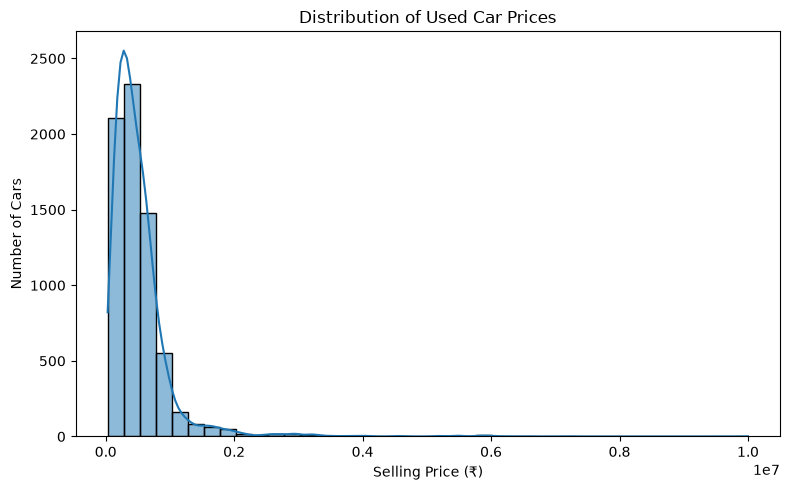

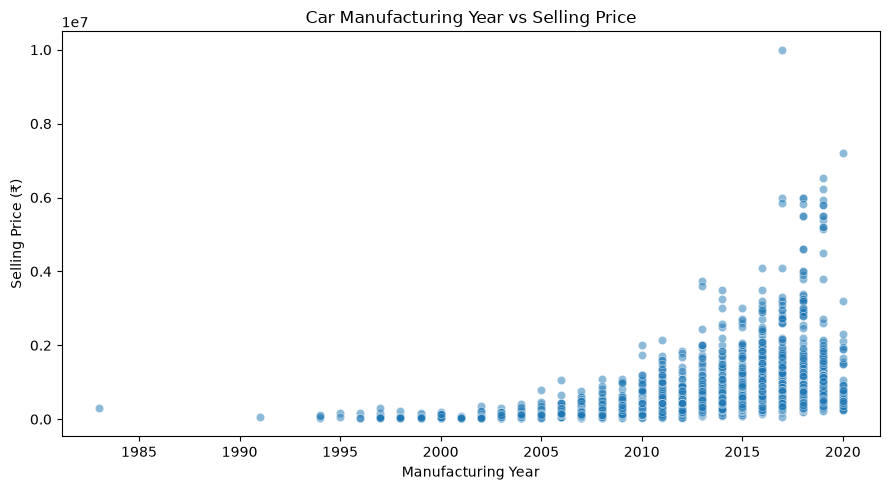

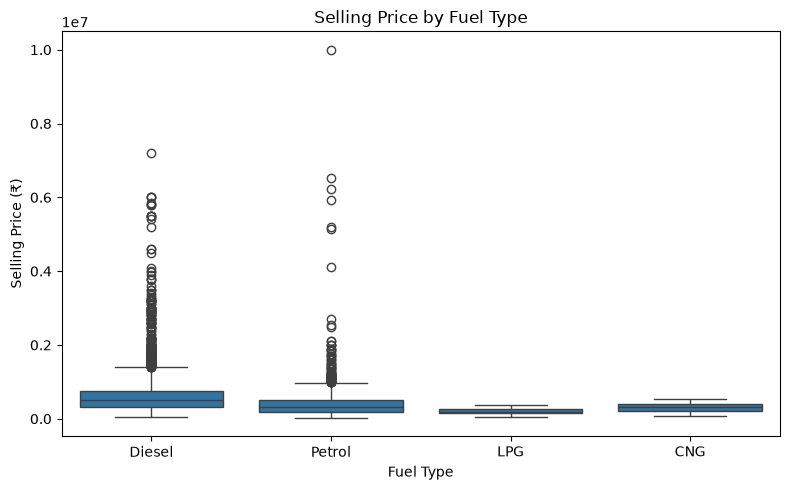

In [9]:

# STEP 8: Explore relationships between car features and price

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Distribution of selling prices
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["selling_price"], bins=40, kde=True)
plt.title("Distribution of Used Car Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

# 2. Car price by manufacturing year
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_clean,
    x="year",
    y="selling_price",
    alpha=0.5
)
plt.title("Car Manufacturing Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()

# 3. Price by fuel type
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_clean,
    x="fuel",
    y="selling_price"
)
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()

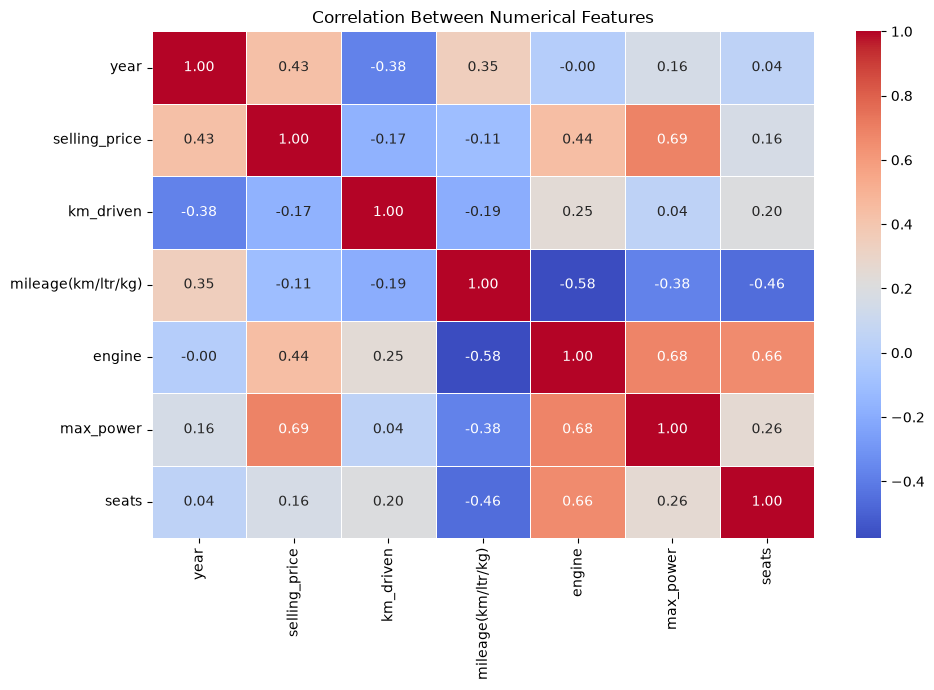


Correlation with selling price:
selling_price         1.000000
max_power             0.688838
engine                0.444760
year                  0.433076
seats                 0.163942
mileage(km/ltr/kg)   -0.107372
km_driven            -0.165620
Name: selling_price, dtype: float64


In [10]:

# STEP 9: Correlation analysis

import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df_clean.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

print("\nCorrelation with selling price:")
print(
    numeric_df.corr()["selling_price"]
    .sort_values(ascending=False)
)

In [11]:

# STEP 10: Inspect features before model preparation

categorical_columns = df_clean.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nMissing values in the full dataset:")
print(df_clean.isnull().sum())

print("\nUnique values in categorical columns:")
for col in categorical_columns:
    print(f"\n{col}: {df_clean[col].nunique()} unique values")
    print(df_clean[col].value_counts().head(10))

print("\nTarget variable summary:")
print(df_clean["selling_price"].describe())

Categorical columns:
['name', 'fuel', 'seller_type', 'transmission', 'owner']

Missing values in the full dataset:
name                  0
year                  0
selling_price         0
km_driven             0
fuel                  0
seller_type           0
transmission          0
owner                 0
mileage(km/ltr/kg)    0
engine                0
max_power             0
seats                 0
dtype: int64

Unique values in categorical columns:

name: 2058 unique values
name
Maruti Swift Dzire VDI      118
Maruti Alto 800 LXI          76
Maruti Alto LXi              69
Maruti Swift VDI             60
Maruti Swift VDI BSIV        56
Maruti Alto K10 VXI          47
Hyundai EON Era Plus         44
Maruti Alto LX               43
Maruti Wagon R VXI BS IV     43
Maruti Ertiga VDI            42
Name: count, dtype: int64

fuel: 4 unique values
fuel
Diesel    3755
Petrol    3077
CNG         56
LPG         38
Name: count, dtype: int64

seller_type: 3 unique values
seller_type
Individual  

C:\Users\sriso\AppData\Local\Temp\ipykernel_28132\1561451345.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_clean.select_dtypes(


In [12]:

# STEP 11: Prepare features and target variable

from sklearn.model_selection import train_test_split

# Select input features
X = df_clean.drop(columns=["selling_price", "name"])

# Select target variable
y = df_clean["selling_price"]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nInput feature columns:")
print(X.columns.tolist())

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Input features shape: (6926, 10)
Target variable shape: (6926,)

Input feature columns:
['year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats']

Training data shape: (5540, 10)
Testing data shape: (1386, 10)
Training target shape: (5540,)
Testing target shape: (1386,)


In [13]:

# STEP 12: Encode categorical features

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical and numerical columns
categorical_columns = [
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

numerical_columns = [
    "year",
    "km_driven",
    "mileage(km/ltr/kg)",
    "engine",
    "max_power",
    "seats"
]

# Create the preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        ("numerical", "passthrough", numerical_columns)
    ]
)

# Fit on training data and transform both datasets
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded training data shape:", X_train_encoded.shape)
print("Encoded testing data shape:", X_test_encoded.shape)

Encoded training data shape: (5540, 20)
Encoded testing data shape: (1386, 20)


In [14]:

# STEP 13: Train Linear Regression Model

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Create the model
model = LinearRegression()

# Train the model using training data
model.fit(X_train_encoded, y_train)

# Predict car prices for test data
y_pred = model.predict(X_test_encoded)

# Evaluate the model
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("MODEL EVALUATION RESULTS")
print("=" * 35)
print(f"R² Score: {r2:.4f}")
print(f"Mean Absolute Error (MAE): ₹{mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ₹{rmse:,.2f}")

# Compare actual and predicted prices
comparison = {
    "Actual Price": y_test.iloc[:10].values,
    "Predicted Price": y_pred[:10].round(2)
}

import pandas as pd

comparison_df = pd.DataFrame(comparison)
print("\nActual vs Predicted Prices:")
display(comparison_df)

MODEL EVALUATION RESULTS
R² Score: 0.5702
Mean Absolute Error (MAE): ₹172,503.20
Root Mean Squared Error (RMSE): ₹307,020.85

Actual vs Predicted Prices:


,Actual Price,Predicted Price
0,550000,380741.40
1,1225000,1223462.10
2,850000,776722.29
3,80000,-11666.70
4,825000,832642.51
5,800000,846573.75
6,229999,350678.73
7,93150,84678.49
8,300000,231713.73
9,493000,556693.11


In [15]:

# STEP 14: Improve the model using log-transformed prices

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Create and train a new model using log-transformed target values
model_log = LinearRegression()

y_train_log = np.log1p(y_train)

model_log.fit(X_train_encoded, y_train_log)

# Predict log prices and convert them back to rupees
y_pred_log = model_log.predict(X_test_encoded)
y_pred_improved = np.expm1(y_pred_log)

# Evaluate predictions in the original price scale
r2_log = r2_score(y_test, y_pred_improved)
mae_log = mean_absolute_error(y_test, y_pred_improved)
rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_improved))

print("LOG-TRANSFORMED MODEL RESULTS")
print("=" * 40)
print(f"R² Score: {r2_log:.4f}")
print(f"MAE: ₹{mae_log:,.2f}")
print(f"RMSE: ₹{rmse_log:,.2f}")

# Compare the first 10 predictions
comparison_df = pd.DataFrame({
    "Actual Price": y_test.iloc[:10].values,
    "Predicted Price": y_pred_improved[:10].round(2)
})

display(comparison_df)

LOG-TRANSFORMED MODEL RESULTS
R² Score: 0.8503
MAE: ₹106,911.84
RMSE: ₹181,221.69


,Actual Price,Predicted Price
0,550000,341477.62
1,1225000,1114199.33
2,850000,785580.55
3,80000,125571.87
4,825000,828714.66
5,800000,833960.16
6,229999,276350.67
7,93150,133016.12
8,300000,213978.09
9,493000,483696.54


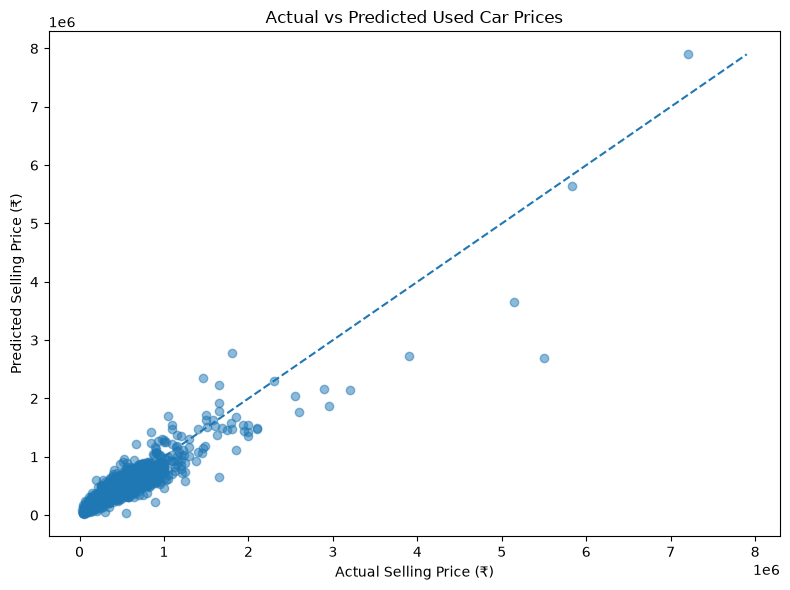

In [16]:

# STEP 15: Actual vs Predicted Price Visualization

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_improved,
    alpha=0.5
)

# Reference line for perfect predictions
min_price = min(y_test.min(), y_pred_improved.min())
max_price = max(y_test.max(), y_pred_improved.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Selling Price (₹)")
plt.ylabel("Predicted Selling Price (₹)")
plt.title("Actual vs Predicted Used Car Prices")
plt.tight_layout()
plt.show()

In [17]:

# Check the variables already available in the notebook
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nFirst 5 training target values:")
print(y_train.head() if hasattr(y_train, "head") else y_train[:5])

Training features: (5540, 10)
Testing features: (1386, 10)
Training target: (5540,)
Testing target: (1386,)

First 5 training target values:
5586    900000
3468    120000
4935    395000
2485    185000
4491    108000
Name: selling_price, dtype: int64


In [18]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model using the encoded training data
rf_model.fit(X_train_encoded, y_train)

# Predict car prices
rf_predictions = rf_model.predict(X_test_encoded)

# Evaluate the model
rf_r2 = r2_score(y_test, rf_predictions)
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

print("RANDOM FOREST MODEL RESULTS")
print("=" * 35)
print(f"R² Score: {rf_r2:.4f}")
print(f"Mean Absolute Error (MAE): ₹{rf_mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ₹{rf_rmse:,.2f}")

RANDOM FOREST MODEL RESULTS
R² Score: 0.9199
Mean Absolute Error (MAE): ₹75,327.79
Root Mean Squared Error (RMSE): ₹132,516.48


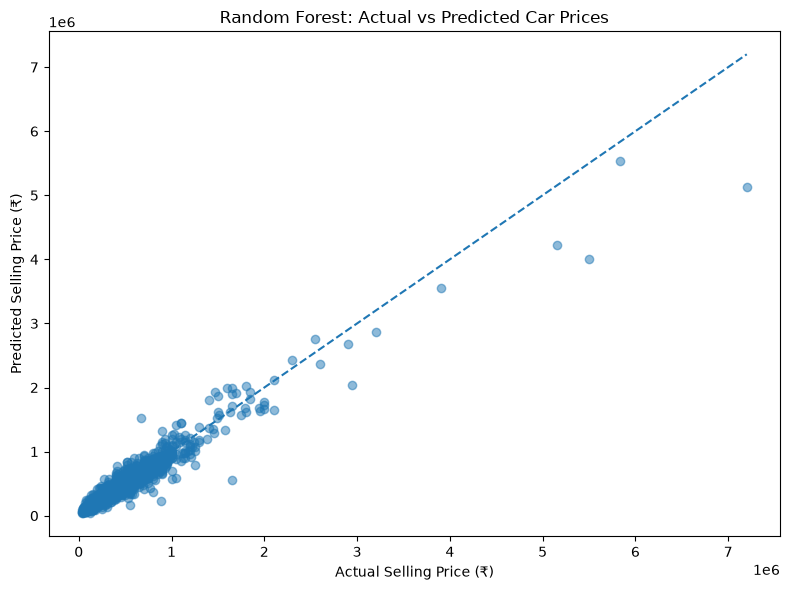

In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.5
)

# Ideal prediction line
min_price = min(y_test.min(), rf_predictions.min())
max_price = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Selling Price (₹)")
plt.ylabel("Predicted Selling Price (₹)")
plt.title("Random Forest: Actual vs Predicted Car Prices")
plt.tight_layout()
plt.show()

TOP 10 IMPORTANT FEATURES
                            Feature  Importance
               numerical__max_power    0.607749
                    numerical__year    0.229612
               numerical__km_driven    0.053561
      numerical__mileage(km/ltr/kg)    0.046959
                  numerical__engine    0.029908
                   numerical__seats    0.009084
   categorical__transmission_Manual    0.003855
categorical__transmission_Automatic    0.003366
           categorical__fuel_Diesel    0.003238
           categorical__fuel_Petrol    0.002987


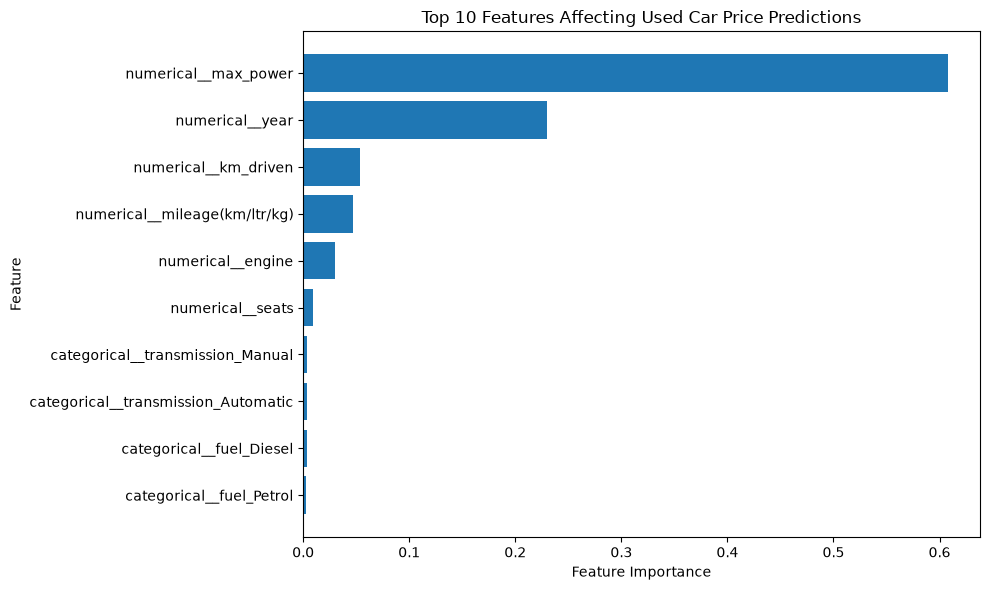

In [20]:

# Feature importance in the Random Forest model

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 10 IMPORTANT FEATURES")
print(importance_df.head(10).to_string(index=False))

# Plot the top 10 features
plt.figure(figsize=(10, 6))

top_features = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features Affecting Used Car Price Predictions")
plt.tight_layout()
plt.show()

In [21]:

# Check whether the Random Forest model is overfitting

from sklearn.metrics import r2_score, mean_absolute_error
import pandas as pd

# Predictions on training and testing data
train_predictions = rf_model.predict(X_train_encoded)
test_predictions = rf_model.predict(X_test_encoded)

# Compare performance
performance_df = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "R2 Score": [
        r2_score(y_train, train_predictions),
        r2_score(y_test, test_predictions)
    ],
    "MAE (₹)": [
        mean_absolute_error(y_train, train_predictions),
        mean_absolute_error(y_test, test_predictions)
    ]
})

print("TRAINING VS TESTING PERFORMANCE")
print("=" * 45)
print(performance_df.to_string(index=False))

# Calculate the R² gap
r2_gap = (
    r2_score(y_train, train_predictions)
    - r2_score(y_test, test_predictions)
)

print(f"\nR² gap: {r2_gap:.4f}")

if r2_gap > 0.10:
    print("Possible overfitting: investigate the performance gap.")
else:
    print("The R² gap is relatively small; check other validation results too.")

TRAINING VS TESTING PERFORMANCE
 Dataset  R2 Score      MAE (₹)
Training  0.984683 31253.243294
 Testing  0.919932 75327.786325

R² gap: 0.0648
The R² gap is relatively small; check other validation results too.


In [22]:

from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
import numpy as np

# Combine preprocessing and model into one pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Use only the training data for cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="r2",
    n_jobs=1
)

print("5-FOLD CROSS-VALIDATION RESULTS")
print("=" * 40)

for fold, score in enumerate(cv_scores, start=1):
    print(f"Fold {fold} R² Score: {score:.4f}")

print(f"\nMean CV R² Score: {np.mean(cv_scores):.4f}")
print(f"Standard Deviation: {np.std(cv_scores):.4f}")

5-FOLD CROSS-VALIDATION RESULTS
Fold 1 R² Score: 0.8980
Fold 2 R² Score: 0.9241
Fold 3 R² Score: 0.9005
Fold 4 R² Score: 0.8685
Fold 5 R² Score: 0.8112

Mean CV R² Score: 0.8805
Standard Deviation: 0.0389


In [23]:

from sklearn.model_selection import GridSearchCV

# Tune Random Forest hyperparameters
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 15, 25],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="r2",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Use training data only
grid_search.fit(X_train, y_train)

print("BEST RANDOM FOREST SETTINGS")
print("=" * 40)
print("Best parameters:", grid_search.best_params_)
print(f"Best mean CV R²: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
BEST RANDOM FOREST SETTINGS
Best parameters: {'model__max_depth': 15, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best mean CV R²: 0.8826


In [24]:

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Best model selected by GridSearchCV
best_model = grid_search.best_estimator_

# Predict on the untouched test set
tuned_predictions = best_model.predict(X_test)

# Evaluate
tuned_r2 = r2_score(y_test, tuned_predictions)
tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))

print("TUNED RANDOM FOREST — TEST RESULTS")
print("=" * 45)
print(f"R² Score: {tuned_r2:.4f}")
print(f"MAE: ₹{tuned_mae:,.2f}")
print(f"RMSE: ₹{tuned_rmse:,.2f}")

# Compare against the original Random Forest test results
print("\nCOMPARISON WITH ORIGINAL MODEL")
print("=" * 45)
print(f"Original test R²: 0.9199")
print(f"Tuned test R²:   {tuned_r2:.4f}")
print(f"Original test MAE: ₹75,327.79")
print(f"Tuned test MAE:   ₹{tuned_mae:,.2f}")

TUNED RANDOM FOREST — TEST RESULTS
R² Score: 0.9195
MAE: ₹74,748.19
RMSE: ₹132,876.63

COMPARISON WITH ORIGINAL MODEL
Original test R²: 0.9199
Tuned test R²:   0.9195
Original test MAE: ₹75,327.79
Tuned test MAE:   ₹74,748.19


In [26]:


from sklearn.metrics import r2_score, mean_absolute_error
import pandas as pd
from sklearn.utils.validation import check_is_fitted

# Check whether the original model is fitted
try:
    check_is_fitted(rf_pipeline)
    original_model = rf_pipeline
    print("Original model is fitted.")
except Exception:
    original_model = None
    print("Original model is not fitted. Skipping its comparison.")

# The tuned model was fitted by GridSearchCV
tuned_train_pred = best_model.predict(X_train)
tuned_test_pred = best_model.predict(X_test)

results = [{
    "Model": "Tuned Random Forest",
    "Train R2": r2_score(y_train, tuned_train_pred),
    "Test R2": r2_score(y_test, tuned_test_pred),
    "Train MAE": mean_absolute_error(y_train, tuned_train_pred),
    "Test MAE": mean_absolute_error(y_test, tuned_test_pred)
}]

# Compare the original model only if it is fitted
if original_model is not None:
    original_train_pred = original_model.predict(X_train)
    original_test_pred = original_model.predict(X_test)

    results.insert(0, {
        "Model": "Original Random Forest",
        "Train R2": r2_score(y_train, original_train_pred),
        "Test R2": r2_score(y_test, original_test_pred),
        "Train MAE": mean_absolute_error(y_train, original_train_pred),
        "Test MAE": mean_absolute_error(y_test, original_test_pred)
    })

comparison = pd.DataFrame(results)
display(comparison.round(4))

Original model is not fitted. Skipping its comparison.


,Model,Train R2,Test R2,Train MAE,Test MAE
0,Tuned Random Forest,0.9824,0.9195,37854.4477,74748.1852


In [27]:

import joblib
from pathlib import Path

# Create a folder for saved models
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the complete tuned preprocessing + model pipeline
model_path = model_dir / "used_car_price_model.pkl"
joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path.resolve())
print("Model type:", type(best_model).__name__)

Model saved successfully!
Saved location: C:\Users\sriso\OneDrive\Documents\AI_Used_Car_Price_Intelligence\notebooks\models\used_car_price_model.pkl
Model type: Pipeline


In [28]:

from pathlib import Path
import joblib

# Locate the main project directory
project_dir = Path.cwd().parent

# Save to the existing main models folder
model_dir = project_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "used_car_price_model.pkl"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Model location:", model_path.resolve())
print("File exists:", model_path.exists())

Model saved successfully!
Model location: C:\Users\sriso\OneDrive\Documents\AI_Used_Car_Price_Intelligence\models\used_car_price_model.pkl
File exists: True
